# 04 · NER, extractive QA and summarisation

In [1]:
import json, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from src.plotting import apply_style, hbar_groups, SERIES, MUTED, TEXT_SECONDARY
from src.preprocess import TextPreprocessor

apply_style()
pd.set_option("display.precision", 3)

def metrics(name):
    with open(os.path.join(ROOT, "results", "metrics", f"{name}.json"), encoding="utf-8") as f:
        return json.load(f)

def split(task, name):
    return TextPreprocessor.load_jsonl(os.path.join(ROOT, "data", "processed", task, f"{name}.jsonl"))

## NER: transformer vs gazetteer (strict span-F1, 95% bootstrap CI)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


,precision,recall,f1,ci_low,ci_high
gazetteer,0.857,0.24,0.375,0.180,0.500
transformer,0.739,0.68,0.708,0.569,0.842


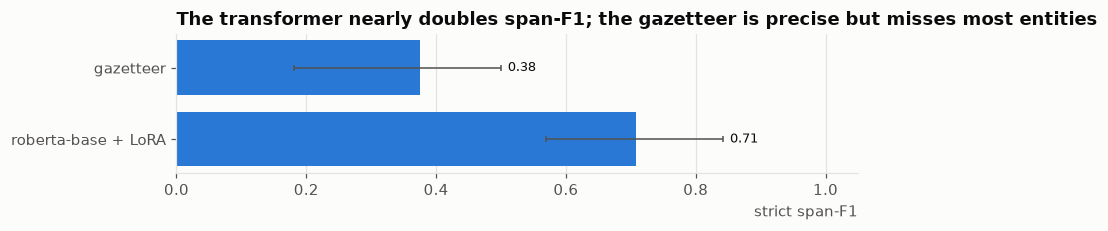

In [2]:
ner = metrics("ner")
nt = pd.DataFrame({k: {"precision": v["precision"], "recall": v["recall"], "f1": v["f1"],
                       "ci_low": v["f1_95ci"][0], "ci_high": v["f1_95ci"][1]} for k, v in ner.items()}).T
fig, ax = plt.subplots(figsize=(8, 2.2))
f1 = nt["f1"].tolist()
hbar_groups(ax, ["gazetteer", "roberta-base + LoRA"], {"span-F1": f1},
            errors={"span-F1": [[f - lo for f, lo in zip(f1, nt["ci_low"])], [hi - f for f, hi in zip(f1, nt["ci_high"])]]},
            fmt="{:.2f}", xlabel="strict span-F1", xlim=(0, 1.05))
ax.set_title("The transformer nearly doubles span-F1; the gazetteer is precise but misses most entities")
fig.tight_layout()
nt

## Extractive QA examples (multi-task model, unseen contexts)

In [3]:
qa = metrics("multitask")["multitask"][0]["qa"]   # seed 42
ex = pd.DataFrame(qa["examples"])
ex["exact"] = [a.lower().strip(". ") == b.lower().strip(". ") for a, b in zip(ex.gold, ex.predicted)]
print(f"EM {qa['exact_match']:.3f}   token F1 {qa['f1']:.3f}  95% CI {qa['f1_95ci']}")
ex

EM 0.462   token F1 0.606  95% CI [0.3615, 0.8085]


,question,gold,predicted,exact
0,Who pays fringe benefits tax?,employers,Fringe benefits tax is paid by employers,False
1,When does the FBT year begin?,1 April,31 March,False
2,What is the FBT rate?,47 percent,47 percent,True
3,What level of government levies payroll tax?,state and territory,Payroll tax,False
4,Which provisions combine the wages of related ...,grouping provisions,grouping provisions,True
5,Where do employers register for payroll tax?,the revenue office in each state where they pa...,with the revenue office,False
6,Which listing rule sets out the continuous dis...,Listing Rule 3.1,3.1,False
7,Which section of the Corporations Act gives co...,section 674,section 674,True
8,What may ASIC issue for suspected breaches?,infringement notices,infringement notices,True
9,How long must an individual hold an asset to r...,at least twelve months,one-third,False


## Summarisation: ROUGE with 95% bootstrap CI

,rouge1,rouge2,rougeL,rougeL_low,rougeL_high
lead-1 (first sentence),0.364,0.181,0.301,0.232,0.374
google/flan-t5-base zero-shot,0.266,0.126,0.227,0.181,0.278
google/flan-t5-base + lora,0.458,0.217,0.376,0.315,0.428


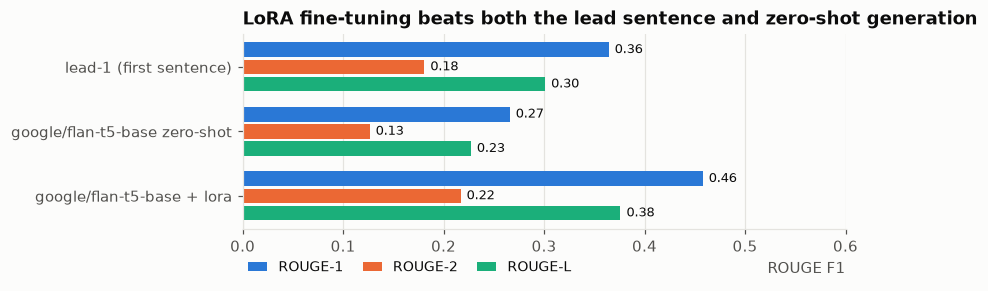

In [4]:
sm = metrics("summarisation")["systems"]
st = pd.DataFrame({k: {m: v[m] for m in ("rouge1", "rouge2", "rougeL")} | {"rougeL_low": v["rougeL_95ci"][0], "rougeL_high": v["rougeL_95ci"][1]}
                   for k, v in sm.items()}).T
fig, ax = plt.subplots(figsize=(8, 2.8))
hbar_groups(ax, list(st.index), {"ROUGE-1": st["rouge1"].tolist(), "ROUGE-2": st["rouge2"].tolist(), "ROUGE-L": st["rougeL"].tolist()},
            fmt="{:.2f}", xlabel="ROUGE F1", xlim=(0, 0.6))
ax.set_title("LoRA fine-tuning beats both the lead sentence and zero-shot generation")
fig.tight_layout()
st

In [5]:
names = list(sm)
pd.DataFrame({"zero-shot": sm[names[1]]["predictions"], "fine-tuned": sm[names[2]]["predictions"]}).head(6)

,zero-shot,fine-tuned
0,The Australian Prudential Regulation Authority...,The Australian Prudential Regulation Authority...
1,Employers in England and Wales are required to...,Employers pay fringe benefits tax on employee ...
2,Identify the goods and services tax (GST).,"Input-taxed supplies, such as residential rent..."
3,Find out if you are protected from unfair dism...,Employees are protected from unfair dismissal ...
4,Understand enterprise bargaining.,"Enterprise bargaining allows employers, employ..."
5,Request a flexible working arrangement if you ...,Employees with at least twelve months of conti...
